In [74]:
import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

from segment_anything import sam_model_registry
from segment_anything import SamAutomaticMaskGenerator
from segment_anything import SamPredictor

In [75]:
sam_checkpoint = "../checkpoints/sam_vit_b_01ec64.pth"

model_type = "vit_b"

device = "cpu"

sam = sam_model_registry[model_type](
    checkpoint=sam_checkpoint
)

sam.to(device=device)

Sam(
  (image_encoder): ImageEncoderViT(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (attn): Attention(
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (mlp): MLPBlock(
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): Linear(in_features=3072, out_features=768, bias=True)
          (act): GELU(approximate='none')
        )
      )
    )
    (neck): Sequential(
      (0): Conv2d(768, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): LayerNorm2d()
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (3)

In [76]:
print(type(sam))

<class 'segment_anything.modeling.sam.Sam'>


In [77]:
mask_generator = SamAutomaticMaskGenerator(
    sam,
    points_per_side=8
)

In [78]:
import os

print(
    os.path.exists(
        "../data/54cae422a6fc6_-_american-muscle-facts-03-0312-xln.jpg"
    )
)

True


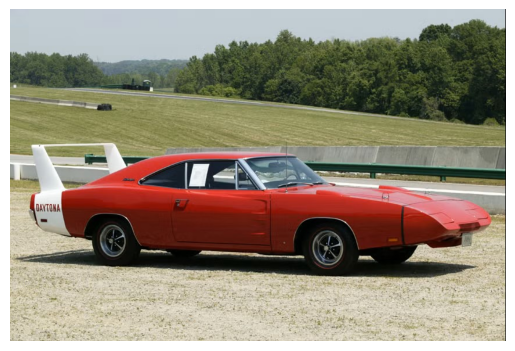

In [79]:
image = cv2.imread("../data/54cae422a6fc6_-_american-muscle-facts-03-0312-xln.jpg")

image = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.imshow(image)
plt.axis("off")
plt.show()

In [80]:
print(image.shape)

(572, 855, 3)


In [81]:
print(device)

cpu


In [82]:
image_small = cv2.resize(
    image,
    (800, 533)
)

print(image_small.shape)

(533, 800, 3)


In [83]:
masks = mask_generator.generate(image_small)

In [84]:
print(len(masks))

16


In [85]:
for i in range(len(masks)):
    print(
        f"Mask {i}: area={masks[i]['area']}"
    )

Mask 0: area=44176
Mask 1: area=115093
Mask 2: area=92031
Mask 3: area=1806
Mask 4: area=47627
Mask 5: area=6285
Mask 6: area=2833
Mask 7: area=17352
Mask 8: area=7270
Mask 9: area=12842
Mask 10: area=4397
Mask 11: area=58520
Mask 12: area=68766
Mask 13: area=2148
Mask 14: area=2977
Mask 15: area=3383


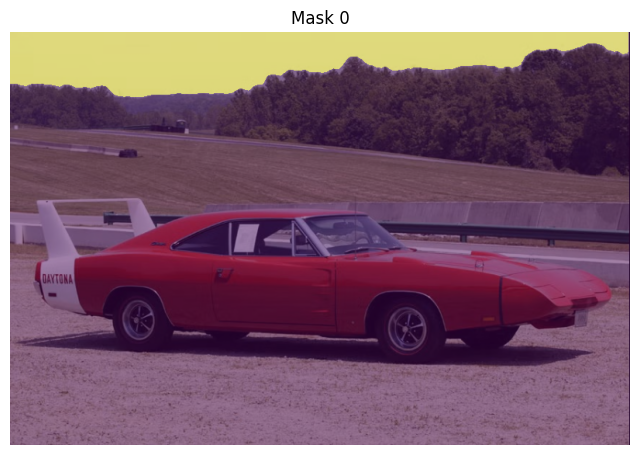

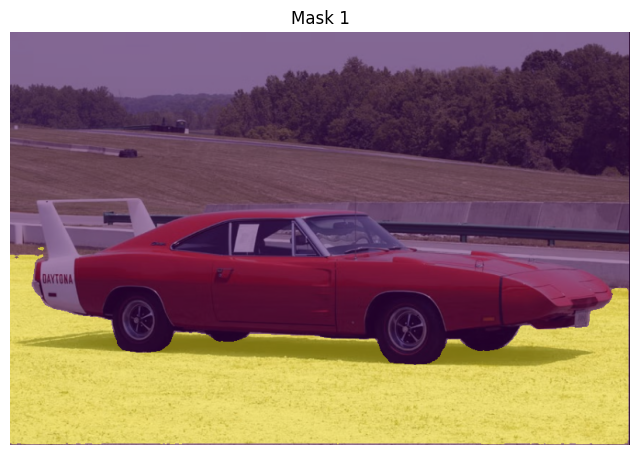

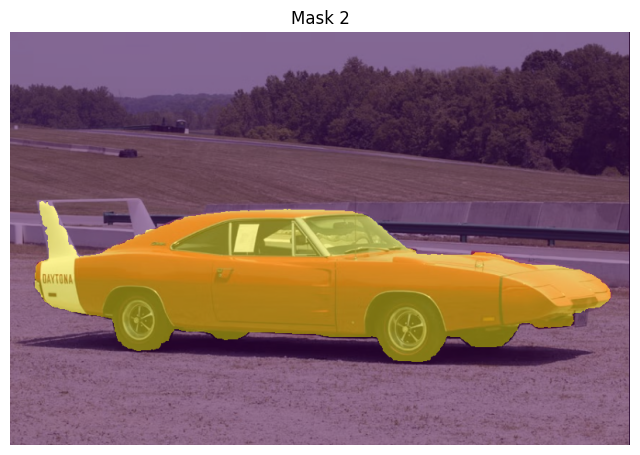

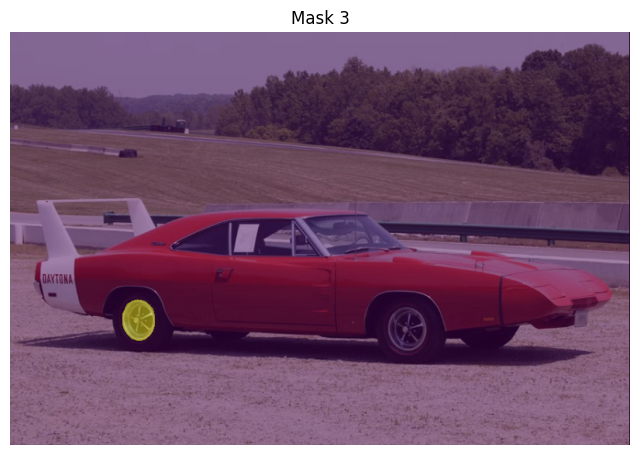

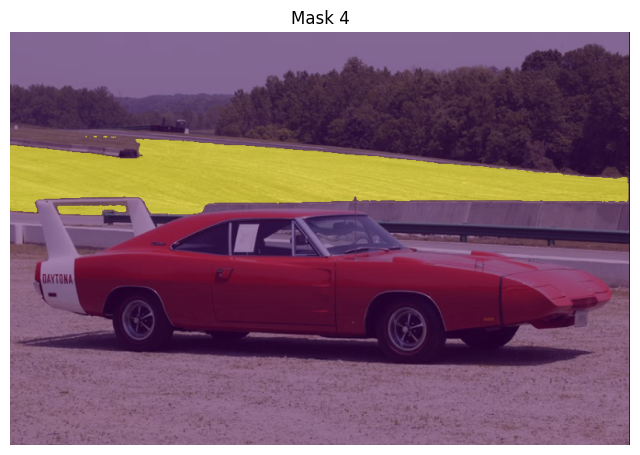

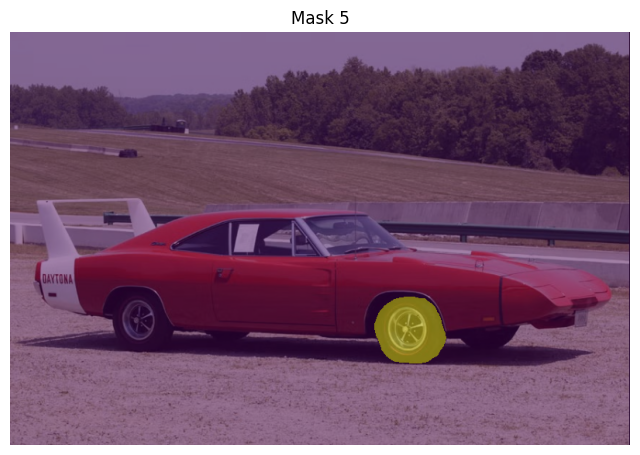

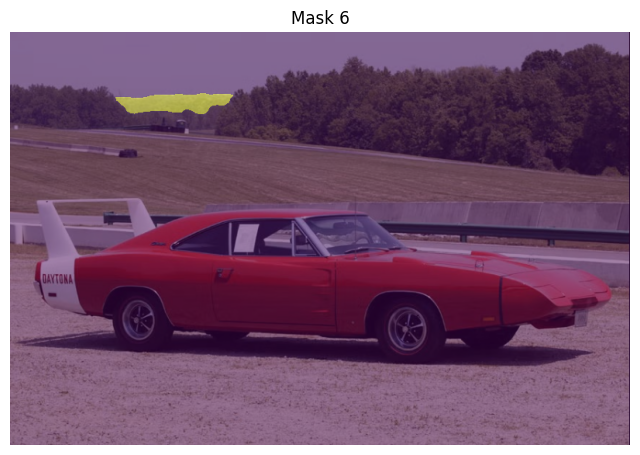

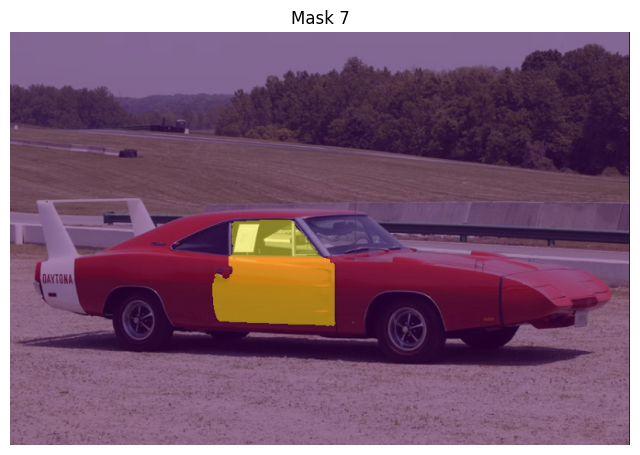

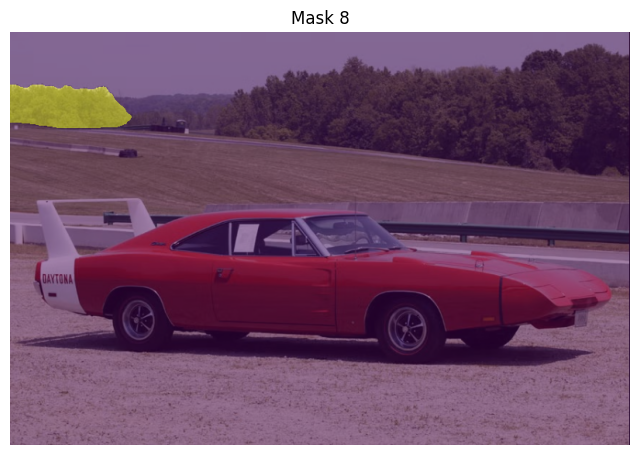

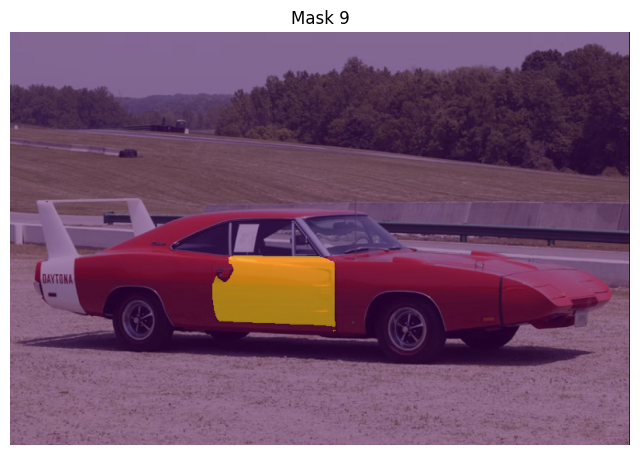

In [86]:
for i in range(min(10, len(masks))):

    plt.figure(figsize=(8,8))

    plt.imshow(image_small)

    plt.imshow(
        masks[i]["segmentation"],
        alpha=0.5
    )

    plt.title(f"Mask {i}")

    plt.axis("off")
    plt.show()

In [87]:
mask = masks[2]["segmentation"]

print(mask.shape)

(533, 800)


In [91]:
masked_image = image_small.copy()

masked_image[~mask] = 0

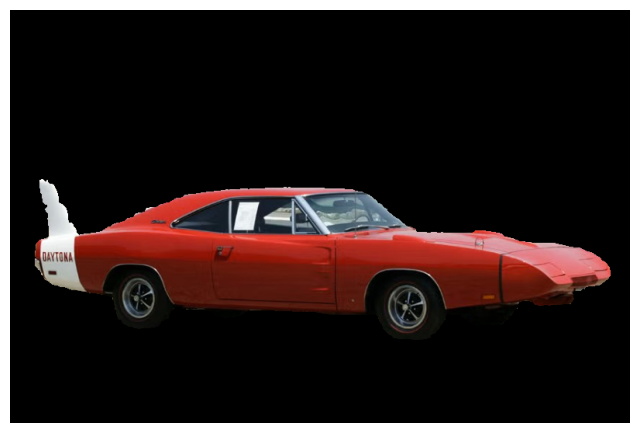

In [89]:
plt.figure(figsize=(8,8))

plt.imshow(masked_image)

plt.axis("off")

plt.show()

In [ ]:
bbox = masks[2]["bbox"]

print(bbox)

[32, 219, 742, 206]


[32, 219, 742, 206]


In [ ]:
x, y, w, h = bbox

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

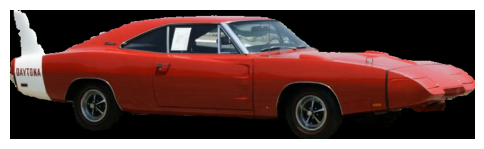

In [ ]:
plt.figure(figsize=(6,6))

plt.imshow(cropped_image)

plt.axis("off")

plt.show()

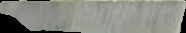

In [92]:
from PIL import Image

crop_pil = Image.fromarray(
    cropped_image
)

crop_pil

In [ ]:
prompt = ["a car"]

In [93]:
from transformers import CLIPProcessor
from transformers import CLIPModel

model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
)

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [ ]:
inputs = processor(
    text=prompt,
    images=crop_pil,
    return_tensors="pt",
    padding=True
)

In [94]:
prompt = ["a car"]

inputs = processor(
    text=prompt,
    images=crop_pil,
    return_tensors="pt",
    padding=True
)

In [95]:
with torch.no_grad():
    outputs = model(**inputs)

In [ ]:
logits = outputs.logits_per_image

print(logits)

tensor([[23.5354]])


In [ ]:
print(logits)

tensor([[23.5354]])


In [ ]:
mask = masks[5]["segmentation"]

print(mask.shape)

(683, 1024)


In [96]:
masked_image = image_small.copy()

masked_image[~mask] = 0

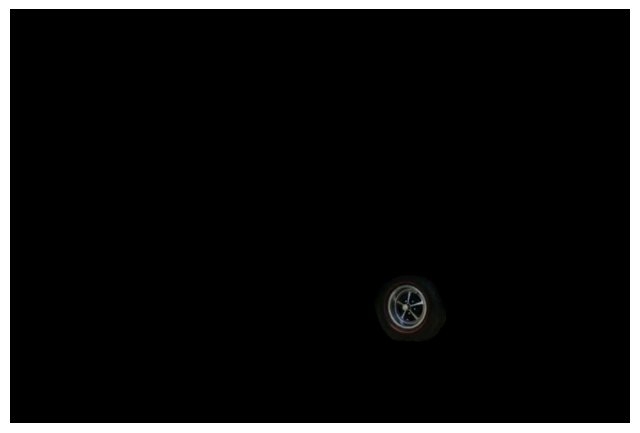

In [ ]:
plt.figure(figsize=(8,8))

plt.imshow(masked_image)

plt.axis("off")

plt.show()

In [97]:
bbox = masks[5]["bbox"]

print(bbox)

[470, 342, 92, 85]


In [ ]:
x, y, w, h = bbox

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

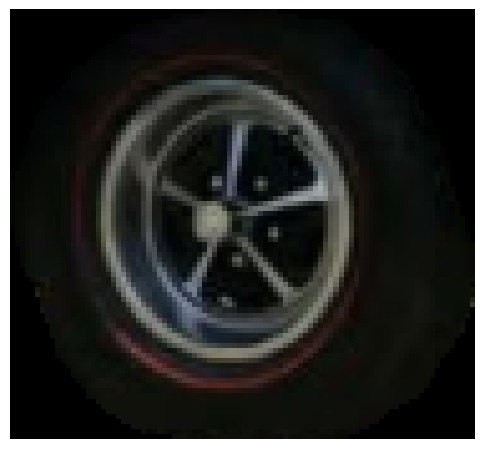

In [ ]:
plt.figure(figsize=(6,6))

plt.imshow(cropped_image)

plt.axis("off")

plt.show()

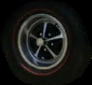

In [ ]:
from PIL import Image

crop_pil = Image.fromarray(
    cropped_image
)

crop_pil

In [ ]:
inputs = processor(
    text=prompt,
    images=crop_pil,
    return_tensors="pt",
    padding=True
)

In [ ]:
with torch.no_grad():
    outputs = model(**inputs)

In [ ]:
logits = outputs.logits_per_image

print(logits)

tensor([[21.1919]])


In [98]:
from PIL import Image
import torch

prompt = ["a car"]

scores = []

for idx, mask_info in enumerate(masks):

    mask = mask_info["segmentation"]

    # Apply mask
    masked_image = image_small.copy()
    masked_image[~mask] = 0

    # Crop using bbox
    x, y, w, h = mask_info["bbox"]

    cropped_image = masked_image[
        y:y+h,
        x:x+w
    ]

    # Skip invalid crops
    if cropped_image.size == 0:
        continue

    # Convert to PIL
    crop_pil = Image.fromarray(cropped_image)

    # CLIP processing
    inputs = processor(
        text=prompt,
        images=crop_pil,
        return_tensors="pt",
        padding=True
    )

    with torch.no_grad():
        outputs = model(**inputs)

    score = outputs.logits_per_image.item()

    scores.append(
        (idx, score)
    )

# Sort descending
scores = sorted(
    scores,
    key=lambda x: x[1],
    reverse=True
)

print("Mask Rankings:")
for idx, score in scores:
    print(
        f"Mask {idx}: {score:.4f}"
    )

Mask Rankings:
Mask 7: 27.6583
Mask 10: 26.2012
Mask 9: 25.8375
Mask 2: 25.6466
Mask 5: 25.3336
Mask 13: 23.9179
Mask 4: 23.8407
Mask 6: 23.7604
Mask 3: 23.7105
Mask 11: 23.5700
Mask 15: 23.5354
Mask 8: 23.3037
Mask 1: 22.8429
Mask 12: 22.7410
Mask 0: 21.1632
Mask 14: 20.3089


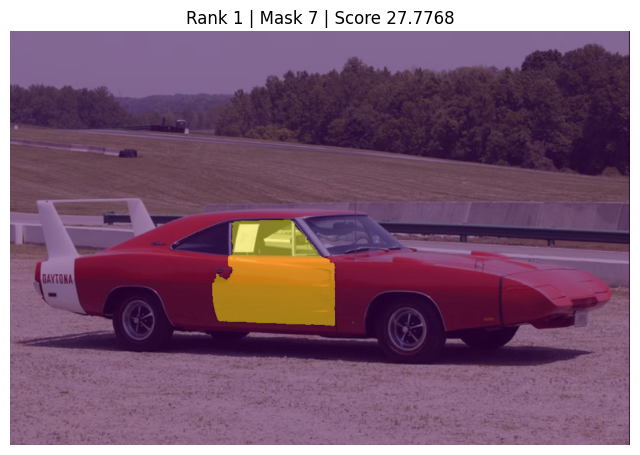

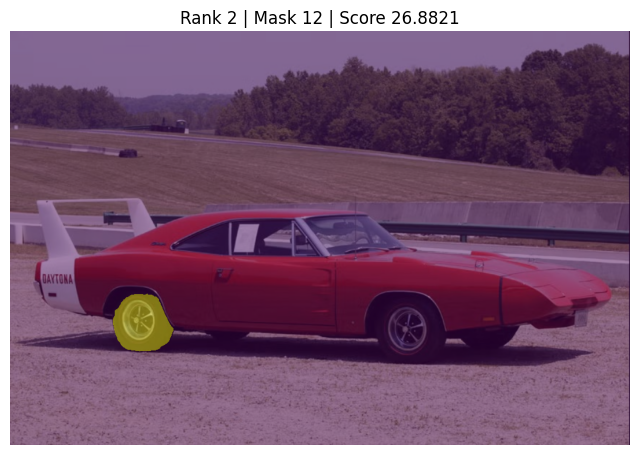

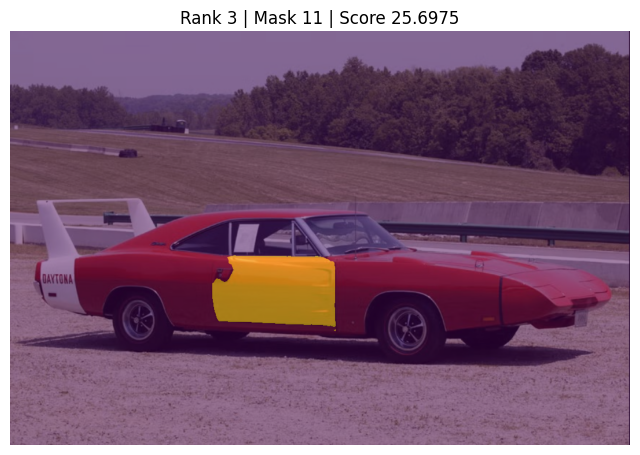

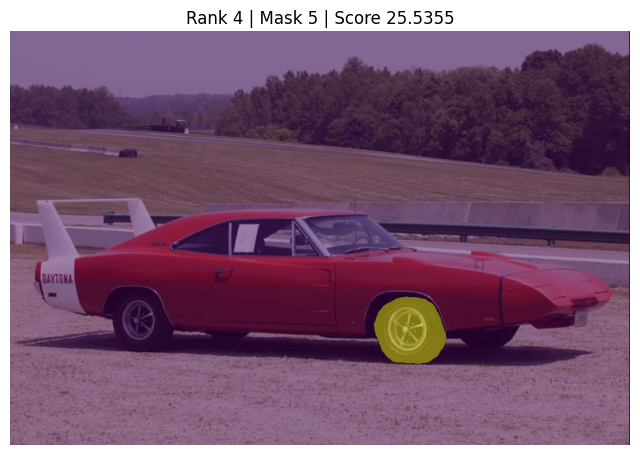

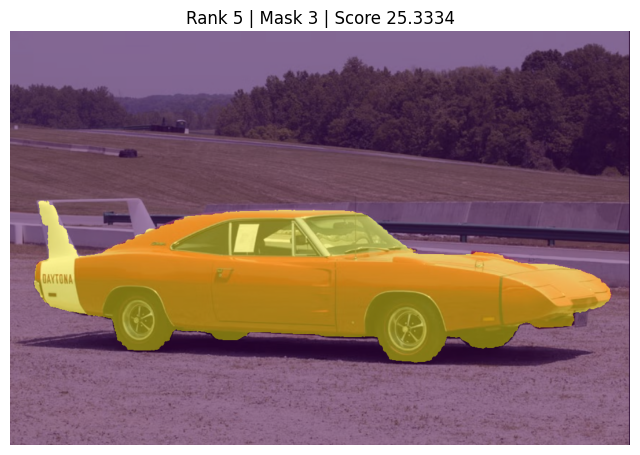

In [ ]:
for rank, (idx, score) in enumerate(scores[:5]):

    plt.figure(figsize=(8,8))

    plt.imshow(image_small)

    plt.imshow(
        masks[idx]["segmentation"],
        alpha=0.5
    )

    plt.title(
        f"Rank {rank+1} | Mask {idx} | Score {score:.4f}"
    )

    plt.axis("off")

    plt.show()

In [99]:
from PIL import Image
import torch


def score_mask(
    image,
    mask_info,
    prompt,
    model,
    processor
):
    
    # Extract mask
    mask = mask_info["segmentation"]
    
    # Apply mask
    masked_image = image.copy()
    masked_image[~mask] = 0
    
    # Get bounding box
    x, y, w, h = mask_info["bbox"]
    
    # Crop region
    cropped_image = masked_image[
        y:y+h,
        x:x+w
    ]
    
    # Safety check
    if cropped_image.size == 0:
        return -float("inf")
    
    # Convert to PIL
    crop_pil = Image.fromarray(
        cropped_image
    )
    
    # CLIP processing
    inputs = processor(
        text=[prompt],
        images=crop_pil,
        return_tensors="pt",
        padding=True
    )
    
    # Inference
    with torch.no_grad():
        outputs = model(**inputs)
    
    score = outputs.logits_per_image.item()
    
    return score

In [ ]:
score = score_mask(
    image_small,
    masks[2],
    "car",
    model,
    processor
)

print(score)

23.414241790771484


In [100]:
def find_best_mask(
    image,
    masks,
    prompt,
    model,
    processor
):
    
    best_score = -float("inf")
    best_idx = None
    
    all_scores = []
    
    for idx, mask_info in enumerate(masks):
        
        score = score_mask(
            image,
            mask_info,
            prompt,
            model,
            processor
        )
        
        all_scores.append(
            (idx, score)
        )
        
        if score > best_score:
            
            best_score = score
            best_idx = idx
    
    return (
        best_idx,
        best_score,
        all_scores
    )

In [101]:
best_idx, best_score, all_scores = find_best_mask(
    image_small,
    masks,
    "car",
    model,
    processor
)

print("Best Mask:", best_idx)
print("Best Score:", best_score)

Best Mask: 7
Best Score: 28.09345245361328


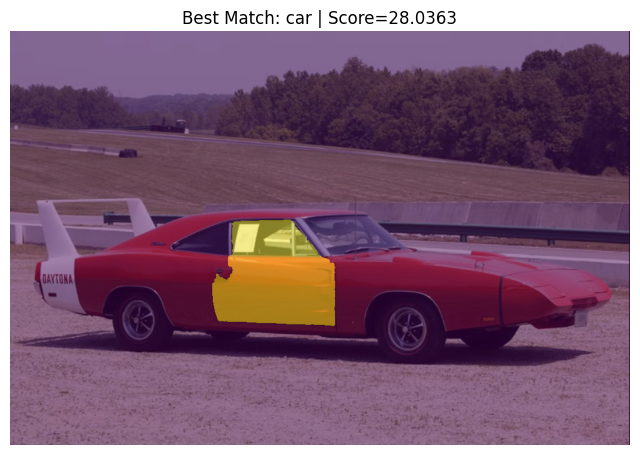

In [ ]:
plt.figure(figsize=(8,8))

plt.imshow(image_small)

plt.imshow(
    masks[best_idx]["segmentation"],
    alpha=0.5
)

plt.title(
    f"Best Match: car | Score={best_score:.4f}"
)

plt.axis("off")

plt.show()

In [102]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 4

mask_info = masks[idx]

mask = mask_info["segmentation"]

masked_image = image.copy()
masked_image[~mask] = 0

x, y, w, h = mask_info["bbox"]

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

plt.figure(figsize=(6,6))
plt.imshow(cropped_image)
plt.title(f"Mask {idx}")
plt.axis("off")
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 572 but size of corresponding boolean axis is 533

In [ ]:
print(image.shape)

(572, 855, 3)


In [ ]:
image_small = cv2.resize(
    image,
    (1024, 683)
)

print(image_small.shape)

(683, 1024, 3)


In [ ]:
print(image_small.shape)

print(mask.shape)

(683, 1024, 3)
(533, 800)


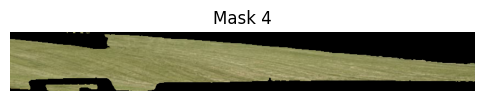

In [103]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 4

mask_info = masks[idx]

mask = mask_info["segmentation"]

masked_image = image_small.copy()
masked_image[~mask] = 0

x, y, w, h = mask_info["bbox"]

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

plt.figure(figsize=(6,6))
plt.imshow(cropped_image)
plt.title(f"Mask {idx}")
plt.axis("off")
plt.show()

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 2

mask_info = masks[idx]

mask = mask_info["segmentation"]

masked_image = image_small.copy()
masked_image[~mask] = 0

x, y, w, h = mask_info["bbox"]

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

plt.figure(figsize=(6,6))
plt.imshow(cropped_image)
plt.title(f"Mask {idx}")
plt.axis("off")
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 683 but size of corresponding boolean axis is 533

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 0

mask_info = masks[idx]

mask = mask_info["segmentation"]

masked_image = image_small.copy()
masked_image[~mask] = 0

x, y, w, h = mask_info["bbox"]

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

plt.figure(figsize=(6,6))
plt.imshow(cropped_image)
plt.title(f"Mask {idx}")
plt.axis("off")
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 683 but size of corresponding boolean axis is 533

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 7

mask_info = masks[idx]

mask = mask_info["segmentation"]

masked_image = image_small.copy()
masked_image[~mask] = 0

x, y, w, h = mask_info["bbox"]

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

plt.figure(figsize=(6,6))
plt.imshow(cropped_image)
plt.title(f"Mask {idx}")
plt.axis("off")
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 683 but size of corresponding boolean axis is 533

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 5

mask_info = masks[idx]

mask = mask_info["segmentation"]

masked_image = image_small.copy()
masked_image[~mask] = 0

x, y, w, h = mask_info["bbox"]

cropped_image = masked_image[
    y:y+h,
    x:x+w
]

plt.figure(figsize=(6,6))
plt.imshow(cropped_image)
plt.title(f"Mask {idx}")
plt.axis("off")
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 683 but size of corresponding boolean axis is 533

In [ ]:
print(len(masks))

16


In [ ]:
print(image_small.shape)

(683, 1024, 3)


In [ ]:
print(image_small.shape)

mask_generator = SamAutomaticMaskGenerator(
    sam,
    points_per_side=8
)

masks = mask_generator.generate(image_small)

print(len(masks))

(683, 1024, 3)
17


In [ ]:
print(image_small.dtype)
print(image_small.min())
print(image_small.max())

uint8
0
255


In [ ]:
print("\nMask Areas:\n")

for i, mask_info in enumerate(masks):
    print(
        f"Mask {i}: {mask_info['area']}"
    )


Mask Areas:

Mask 0: 189345
Mask 1: 72342
Mask 2: 2964
Mask 3: 151346
Mask 4: 78016
Mask 5: 10395
Mask 6: 4634
Mask 7: 28349
Mask 8: 95950
Mask 9: 11957
Mask 10: 113167
Mask 11: 21062
Mask 12: 7253
Mask 13: 3529
Mask 14: 4854
Mask 15: 8362
Mask 16: 5593


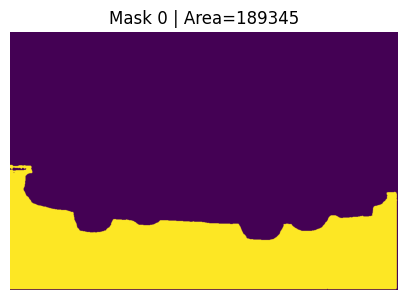

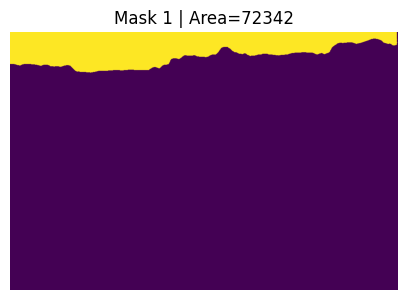

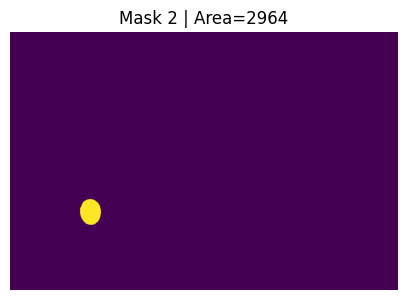

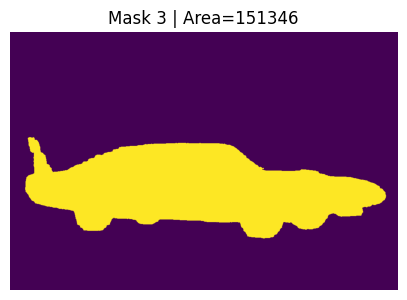

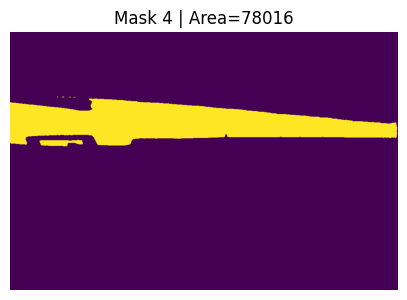

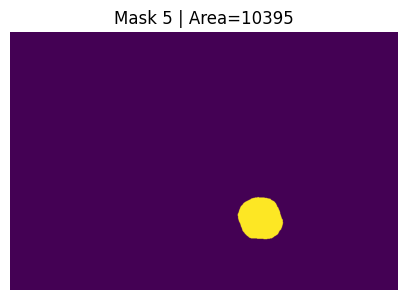

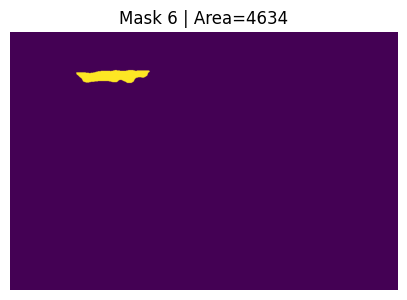

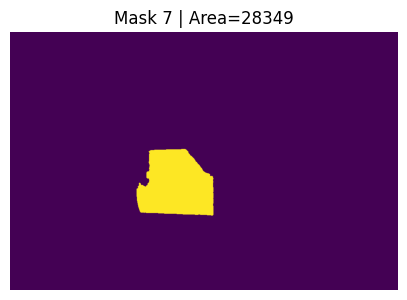

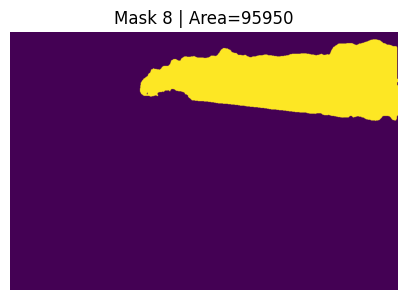

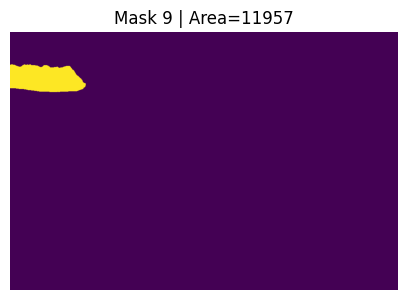

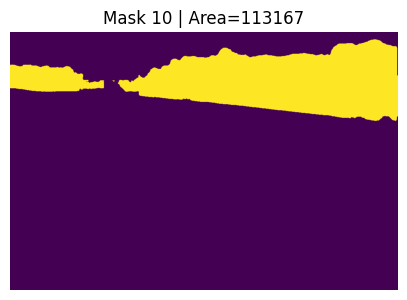

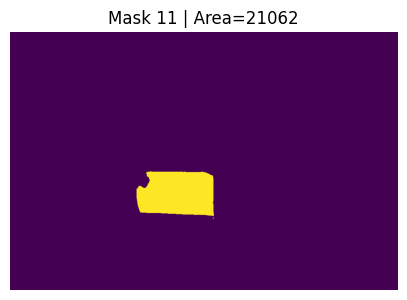

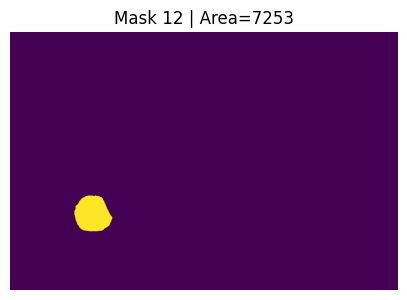

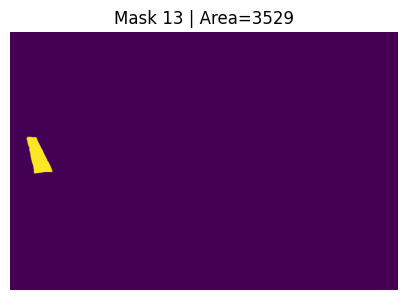

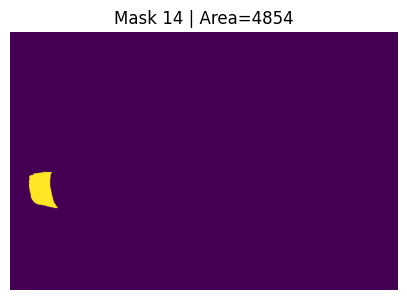

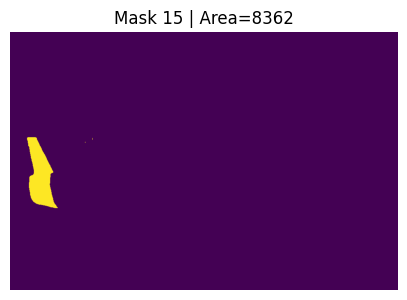

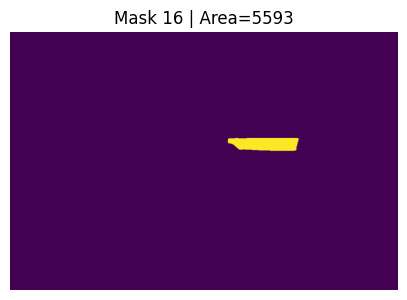

In [ ]:
import matplotlib.pyplot as plt

for idx, mask_info in enumerate(masks):

    plt.figure(figsize=(5,5))

    plt.imshow(mask_info["segmentation"])

    plt.title(
        f"Mask {idx} | Area={mask_info['area']}"
    )

    plt.axis("off")

    plt.show()

In [ ]:
for idx, score in scores:
    print(
        f"Mask {idx}: {score:.4f}"
    )

Mask 7: 27.7768
Mask 12: 26.8821
Mask 11: 25.6975
Mask 5: 25.5355
Mask 3: 25.3334
Mask 2: 24.3700
Mask 4: 24.2796
Mask 0: 24.2324
Mask 6: 24.0331
Mask 13: 23.6868
Mask 15: 23.5729
Mask 9: 23.4472
Mask 16: 23.3832
Mask 8: 23.3179
Mask 10: 23.0915
Mask 14: 22.5968
Mask 1: 21.6467


In [108]:
from PIL import Image
import torch

def score_mask_bbox(
    image,
    mask_info,
    prompt,
    model,
    processor
):

    x, y, w, h = mask_info["bbox"]

    cropped_image = image[
        y:y+h,
        x:x+w
    ]

    if cropped_image.size == 0:
        return -float("inf")

    crop_pil = Image.fromarray(
        cropped_image
    )

    inputs = processor(
        text=[prompt],
        images=crop_pil,
        return_tensors="pt",
        padding=True
    )

    with torch.no_grad():
        outputs = model(**inputs)

    return outputs.logits_per_image.item()

In [109]:
print(score_mask_bbox)

<function score_mask_bbox at 0x000001CAA20DBB00>


In [110]:
for idx in [3, 7, 12]:

    masked_score = score_mask(
        image=image_small,
        mask_info=masks[idx],
        prompt="car",
        model=model,
        processor=processor
    )

    bbox_score = score_mask_bbox(
        image=image_small,
        mask_info=masks[idx],
        prompt="car",
        model=model,
        processor=processor
    )

    print(f"\nMask {idx}")
    print(f"Masked Score : {masked_score:.4f}")
    print(f"BBox Score   : {bbox_score:.4f}")


Mask 3
Masked Score : 22.5982
BBox Score   : 22.6125

Mask 7
Masked Score : 28.0935
BBox Score   : 26.2442

Mask 12
Masked Score : 22.9781
BBox Score   : 22.9525


In [107]:
import sys

sys.path.append("..")

for idx in [3, 7, 12]:

    masked_score = score_mask(
        image=image_small,
        mask_info=masks[idx],
        prompt="a car",
        model=model,
        processor=processor
    )

    bbox_score = score_mask_bbox(
        image=image_small,
        mask_info=masks[idx],
        prompt="car",
        model=model,
        processor=processor
    )

    print(f"\nMask {idx}")
    print(f"Masked Score : {masked_score:.4f}")
    print(f"BBox Score   : {bbox_score:.4f}")

NameError: name 'score_mask_bbox' is not defined

In [111]:
import torch
print(torch.cuda.is_available())

False
